In [14]:
from torchvision import transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
import os

def load_datasets(base_path, train_batch_size, test_batch_size):
    # Define preprocessing transforms
    transform = transforms.Compose([
        transforms.Resize((75, 75)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    # Load training and test datasets
    train_dataset = ImageFolder(
        root=os.path.join(base_path, "train"),
        transform=transform
    )

    test_dataset = ImageFolder(
        root=os.path.join(base_path, "test"),
        transform=transform
    )

    # Create data loaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=train_batch_size,
        shuffle=True,
        num_workers=2
    )
    
    test_loader = DataLoader(
        test_dataset,
        batch_size=test_batch_size,
        shuffle=False,
        num_workers=2
    )
    n_classes = len(train_dataset.classes)
    return train_loader, test_loader, n_classes

In [15]:
import torch.nn as nn
import torchvision.models as models

HIDDEN_LAYER_SIZE = 1000

class MalwareClassifier(nn.Module):
    def __init__(self, n_classes):
        super(MalwareClassifier, self).__init__()

        self.resnet = models.resnet50(weights='DEFAULT')

        for param in self.resnet.parameters():
            param.requires_grad = False

        num_features = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Linear(num_features, HIDDEN_LAYER_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_LAYER_SIZE, n_classes)
        )

    def forward(self, x):
        return self.resnet(x)

In [16]:
def predict(model, test_data):
    model.eval()

    with torch.no_grad():
        output = model(test_data)
        _, predicted = torch.max(output.data, 1)
    return predicted

In [17]:
def compute_accuracy(n_correct, n_total):
    return round(100 * n_correct / n_total, 2 )

def evaluate(model, test_loader):
    model.eval()
    n_correct = 0
    n_total = 0

    with torch.no_grad():
        for data, target in test_loader:
            predicted = predict(model, data)
            n_total += target.size(0)
            n_correct += (predicted == target).sum().item()
    accuracy = compute_accuracy(n_correct, n_total)
    return accuracy

In [18]:
import torch 
import time

def train(model, train_loader, n_epochs, verbose=False):
    model.train()
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters())

    training_data = {"accuracy": [], "loss": []}

    for epoch in range(n_epochs):
        running_loss = 0
        n_total = 0
        n_correct = 0
        checkpoint = time.time() * 1000

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, predicted = outputs.max(1)
            n_total += labels.size(0)
            n_correct += predicted.eq(labels).sum().item()
            running_loss += loss.item()

        epoch_loss = running_loss /len(train_loader)
        epoch_duration = int(time.time() * 1000 - checkpoint)
        epoch_accuracy =  compute_accuracy(n_correct, n_total)

        training_data["accuracy"].append(epoch_accuracy)
        training_data["loss"].append(epoch_loss)

        if verbose:
            print(f"[i] Epoch {epoch+1} of {n_epochs}: Acc: {epoch_accuracy:.2f}% Loss: {epoch_loss:.4f} (Took {epoch_duration} ms).")    
    return training_data


In [19]:
import matplotlib.pyplot as plt

def plot(data, title, label, xlabel, ylabel):
    # HTB Color Palette
    htb_green = "#9FEF00"
    node_black = "#141D2B"
    hacker_grey = "#A4B1CD"

    # plot
    plt.figure(figsize=(10, 6), facecolor=node_black)
    plt.plot(range(1, len(data)+1), data, label=label, color=htb_green)
    plt.title(title, color=htb_green)
    plt.xlabel(xlabel, color=htb_green)
    plt.ylabel(ylabel, color=htb_green)
    plt.xticks(color=hacker_grey)
    plt.yticks(color=hacker_grey)
    ax = plt.gca()
    ax.set_facecolor(node_black)
    ax.spines['bottom'].set_color(hacker_grey)
    ax.spines['top'].set_color(node_black)
    ax.spines['right'].set_color(node_black)
    ax.spines['left'].set_color(hacker_grey)

    legend = plt.legend(facecolor=node_black, edgecolor=hacker_grey, fontsize=10)
    plt.setp(legend.get_texts(), color=htb_green)
    
    plt.show()

def plot_training_accuracy(training_data):
    plot(training_data['accuracy'], "Training Accuracy", "Accuracy", "Epoch", "Accuracy (%)")

def plot_training_loss(training_data):
    plot(training_data['loss'], "Training Loss", "Loss", "Epoch", "Loss")


In [20]:
def save_model(model, path):
    model_scripted = torch.jit.script(model)
    model_scripted.save(path)

[i] Starting training...
[i] Epoch 1 of 10: Acc: 60.17% Loss: 1.4340 (Took 120311 ms).
[i] Epoch 2 of 10: Acc: 87.08% Loss: 0.4065 (Took 88861 ms).
[i] Epoch 3 of 10: Acc: 90.51% Loss: 0.2590 (Took 85101 ms).
[i] Epoch 4 of 10: Acc: 93.15% Loss: 0.2009 (Took 89602 ms).
[i] Epoch 5 of 10: Acc: 93.07% Loss: 0.1877 (Took 86717 ms).
[i] Epoch 6 of 10: Acc: 95.05% Loss: 0.1557 (Took 87211 ms).
[i] Epoch 7 of 10: Acc: 95.72% Loss: 0.1285 (Took 127088 ms).
[i] Epoch 8 of 10: Acc: 95.70% Loss: 0.1182 (Took 89114 ms).
[i] Epoch 9 of 10: Acc: 96.30% Loss: 0.1140 (Took 89259 ms).
[i] Epoch 10 of 10: Acc: 96.53% Loss: 0.0954 (Took 90681 ms).
[i] Inference accuracu: 87.61%.


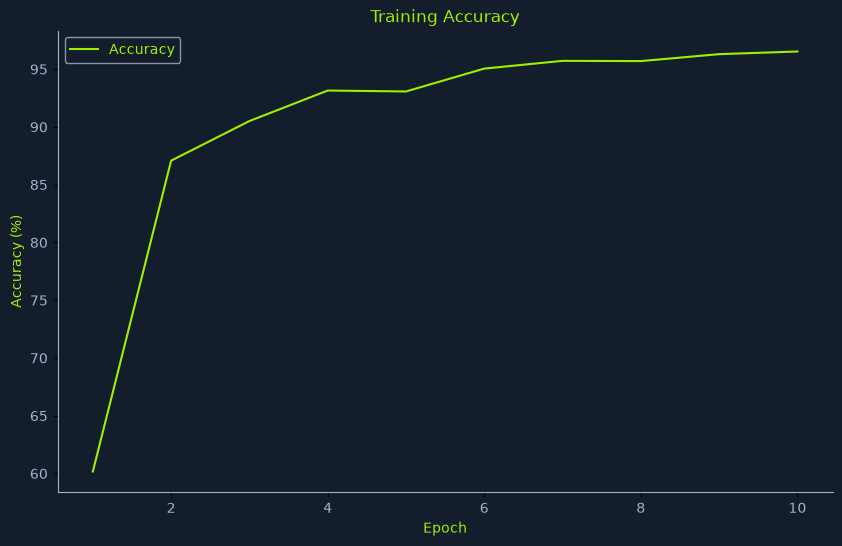

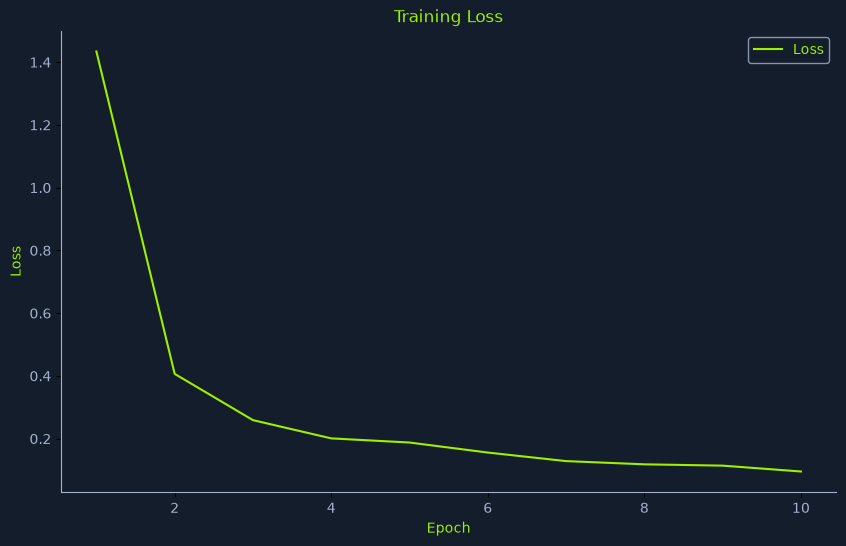

In [21]:
import ssl
import urllib.request

# corporate SSL interception workaround for torch.hub downloads
ssl_ctx = ssl._create_unverified_context()
urllib.request.install_opener(
    urllib.request.build_opener(urllib.request.HTTPSHandler(context=ssl_ctx))
)

N_EPOCHS = 10
DATA_PATH = "./newdata/"
TRAINING_BATCH_SIZE = 512
TEST_BATCH_SIZE = 1024
HIDDEN_LAYER_SIZE = 1000
MODEL_FILE = "malware_classifier.pth"


train_loader, test_loader, n_classes = load_datasets(DATA_PATH, TRAINING_BATCH_SIZE, TEST_BATCH_SIZE)

model = MalwareClassifier(n_classes)

print("[i] Starting training...")
training_information = train(model, train_loader, N_EPOCHS, verbose=True)

save_model(model, MODEL_FILE)

accuracy = evaluate(model, test_loader)
print(f"[i] Inference accuracu: {accuracy}%.")

plot_training_accuracy(training_information)
plot_training_loss(training_information)